# Wadi Ghadir – joint gravity and magnetic inversion with SimPEG (cross-gradient)

**Wadi Ghadir, Eastern Desert, Egypt · complete Bouguer anomaly and total-field magnetic anomaly**

**Written by Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

Notebooks 06 and 07 inverted the gravity and the magnetic data separately. The two models were found independently:
where a body is both dense and magnetic, nothing forces its edges to coincide in the two models. This notebook inverts
**both data sets at once**, for a density contrast Δρ and a susceptibility χ on the same mesh, each **compact**
(sparse norms, as in notebooks 06 and 07), coupled by the **cross-gradient** term of Gallardo & Meju (2003):

$$\phi(\rho, \chi) = \phi_d^{grav}(\rho) + \phi_d^{mag}(\chi) + \beta_1 \phi_m(\rho) + \beta_2 \phi_m(\chi) + \lambda\, \phi_{cg}(\rho, \chi), \qquad
\phi_{cg} = \sum_{cells} \left| \nabla\rho \times \nabla\chi \right|^2 .$$

The cross product of the two gradients vanishes where they are parallel or antiparallel, or where either model is flat. The coupling therefore
asks for **the same structure** (boundaries in the same places) without imposing any relation between density and
susceptibility values: a dense body may be magnetic or not.

| Step | Content |
|---:|---|
| 1 | Both data sets, prepared exactly as in notebooks 06 and 07 |
| 2 | The common mesh |
| 3 | The separate models of notebooks 06 and 07 |
| 4 | The joint problem: one model vector, two simulations, two misfits, two regularisations and the cross-gradient |
| 5 | Run the joint inversion |
| 6 | Data fit of both data sets |
| 7 | Separate and joint models side by side |
| 8 | Structural similarity: the normalised cross-gradient |
| 9 | Density against susceptibility, and a joint classification |
| 10 | Export |

Run notebooks 06 and 07 first (their models are compared here). The joint inversion takes a few minutes.

## 0  Set-up

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}
import contextlib
import io
import json
import logging
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

import discretize
import simpeg
from simpeg import data, data_misfit, directives, inverse_problem, inversion, maps, optimization, regularization
from simpeg.potential_fields import gravity, magnetics

from wghadir import inversion as W

OUT_DIR = os.path.join(REPO, "outputs", "inversion")
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("SimPEG", simpeg.__version__, "| discretize", discretize.__version__, "| outputs in", os.path.abspath(OUT_DIR))

SimPEG 0.25.2 | discretize 0.12.0 | outputs in /home/user/MooSobh/outputs/inversion


## 1  Both data sets

The gravity and magnetic data are prepared with the same functions and default parameters as in notebooks 06 and 07:
residual complete Bouguer anomaly (regional of notebook 03 removed) and TMA minus a plane, both block-median thinned at
400 m, with the same uncertainties. If you changed the parameters there, change them here too.

In [2]:
# ✏️ PARAMETERS – edit and re-run from here
RHO_REDUCTION, GRAV_SENSOR_M = 2.67, 0.25
GRAV_FLOOR_MGAL, GRAV_PERCENT = 0.05, 0.02
MAG_SENSOR_M, MAG_TREND_DEGREE = 2.0, 1
MAG_FLOOR_NT, MAG_PERCENT = 10.0, 0.05
BLOCK_M = 400.0

In [3]:
# ▶ PROCESSING
grav = W.load_gravity(REPO, rho=RHO_REDUCTION, sensor_m=GRAV_SENSOR_M)
grav["residual"] = grav.cb - W.regional_from_grid(REPO, grav.e.values, grav.n.values)
gb = W.block_median(grav, ["residual"], BLOCK_M)
g_obs = gb.residual.values - np.median(gb.residual.values)             # mGal, positive down
g_unc = GRAV_FLOOR_MGAL + GRAV_PERCENT * np.abs(g_obs)

mag, FIELD = W.load_magnetics(REPO, sensor_m=MAG_SENSOR_M)
mag["residual"] = mag.tma - W.polynomial_trend(mag.e.values, mag.n.values, mag.tma.values, MAG_TREND_DEGREE)
mb = W.block_median(mag, ["residual"], BLOCK_M)
m_obs = mb.residual.values - np.median(mb.residual.values)              # nT
m_unc = MAG_FLOOR_NT + MAG_PERCENT * np.abs(m_obs)
print(f"gravity: {len(gb)} data, {g_obs.min():.2f} … {g_obs.max():.2f} mGal | magnetics: {len(mb)} data, {m_obs.min():.0f} … {m_obs.max():.0f} nT")

gravity: 481 data, -9.43 … 4.25 mGal | magnetics: 496 data, -557 … 1347 nT


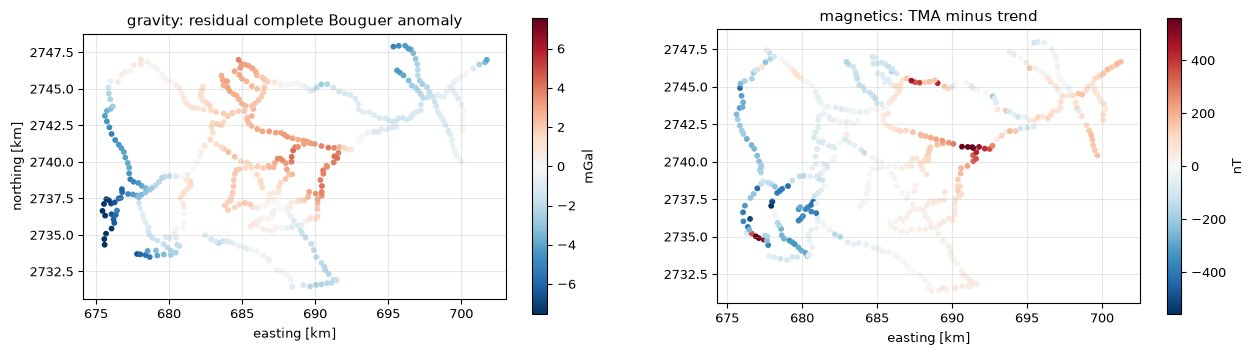

In [4]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, df, v, unit, title in ((axes[0], gb, g_obs, "mGal", "gravity: residual complete Bouguer anomaly"), (axes[1], mb, m_obs, "nT", "magnetics: TMA minus trend")):
    lim = np.percentile(np.abs(v), 99)
    sc = ax.scatter(df.e / 1000, df.n / 1000, c=v, s=10, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set(aspect="equal", title=title, xlabel="easting [km]")
    plt.colorbar(sc, ax=ax, label=unit, shrink=0.8)
axes[0].set_ylabel("northing [km]")
plt.show()

## 2  The common mesh

The same mesh and active cells as in notebooks 06 and 07.

In [5]:
# ✏️ PARAMETERS – edit and re-run from here
CORE_DX_M = 400.0          # horizontal core cell size
CORE_DZ_M = 100.0          # vertical core cell size
N_CORE_Z = 20              # core layers (100 m each) below the top of the mesh
N_PAD_XY, N_PAD_Z = 5, 8   # padding cells, expanding by 1.3
REGION_PAD_M = 1000.0      # margin around all gravity and magnetic data (same mesh in notebooks 06, 07 and 08)

In [6]:
# ▶ PROCESSING
grav_all = W.load_gravity(REPO)
mag_all, FIELD = W.load_magnetics(REPO)
region = W.survey_region(grav_all, mag_all, pad_m=REGION_PAD_M)        # same for both data sets
topo = W.topography(REPO, region)
inside = (topo[:, 0] >= region[0]) & (topo[:, 0] <= region[1]) & (topo[:, 1] >= region[2]) & (topo[:, 1] <= region[3])
z_top = np.ceil(topo[inside, 2].max() / CORE_DZ_M) * CORE_DZ_M
mesh = W.build_mesh(region, dx=CORE_DX_M, dz=CORE_DZ_M, n_core_z=N_CORE_Z, n_pad_xy=N_PAD_XY, n_pad_z=N_PAD_Z, z_top=z_top)
active = W.active_cells(mesh, topo)
n_active = int(active.sum())
print(f"region {(region[1] - region[0]) / 1000:.1f} × {(region[3] - region[2]) / 1000:.1f} km; topography {topo[inside, 2].min():.0f}–{topo[inside, 2].max():.0f} m")
print(f"mesh {mesh.shape_cells} = {mesh.n_cells:,} cells, {n_active:,} active (below the topography); "
      f"depth extent {mesh.h[2].sum() / 1000:.1f} km, top at {z_top:.0f} m")

region 28.3 × 18.7 km; topography 0–771 m
mesh (81, 57, 28) = 129,276 cells, 105,895 active (below the topography); depth extent 5.1 km, top at 800 m


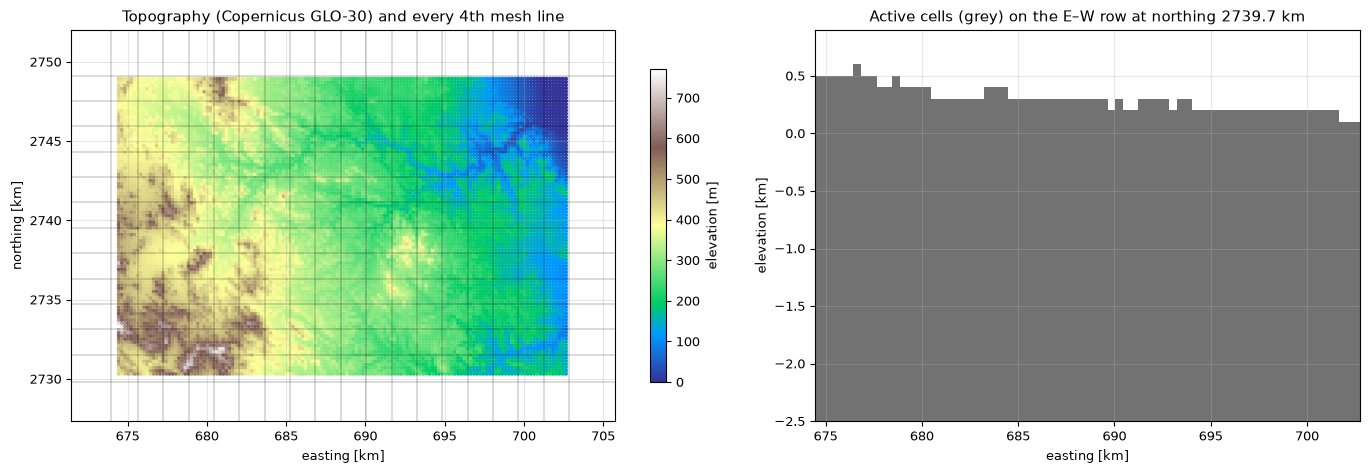

In [7]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ti = topo[inside]
sc = axes[0].scatter(ti[:, 0] / 1000, ti[:, 1] / 1000, c=ti[:, 2], s=4, cmap="terrain", vmin=0)
for xx in mesh.nodes_x[::4]:
    axes[0].axvline(xx / 1000, color="k", lw=0.2)
for yy in mesh.nodes_y[::4]:
    axes[0].axhline(yy / 1000, color="k", lw=0.2)
axes[0].set(xlim=(region[0] / 1000 - 3, region[1] / 1000 + 3), ylim=(region[2] / 1000 - 3, region[3] / 1000 + 3), aspect="equal",
            xlabel="easting [km]", ylabel="northing [km]", title="Topography (Copernicus GLO-30) and every 4th mesh line")
plt.colorbar(sc, ax=axes[0], label="elevation [m]", shrink=0.8)
j = mesh.shape_cells[1] // 2
act3 = active.reshape(mesh.shape_cells, order="F")[:, j, :].T
axes[1].pcolormesh(mesh.nodes_x / 1000, mesh.nodes_z / 1000, act3, cmap="Greys", shading="flat", vmin=0, vmax=1.6)
axes[1].set(xlim=(region[0] / 1000, region[1] / 1000), ylim=(-2.5, z_top / 1000 + 0.1), xlabel="easting [km]", ylabel="elevation [km]",
            title=f"Active cells (grey) on the E–W row at northing {mesh.cell_centers_y[j] / 1000:.1f} km")
plt.tight_layout()
plt.show()

## 3  The separate models

The compact models of notebooks 06 and 07 (`outputs/inversion/gravity_model.npz`, `magnetic_model.npz`), checked
against the mesh of this notebook.

In [8]:
# ▶ PROCESSING
sep_g = np.load(os.path.join(OUT_DIR, "gravity_model.npz"))
sep_m = np.load(os.path.join(OUT_DIR, "magnetic_model.npz"))
assert np.array_equal(sep_g["active"], active) and np.array_equal(sep_m["active"], active), "run notebooks 06 and 07 with the same mesh first"
rho_sep, chi_sep = sep_g["rho_gcc"], sep_m["chi_SI"]
print(f"separate models: Δρ {rho_sep.min():.3f} … {rho_sep.max():.3f} g/cm³; χ {chi_sep.min():.4f} … {chi_sep.max():.4f} SI")

separate models: Δρ -0.300 … 0.300 g/cm³; χ 0.0000 … 0.3000 SI


## 4  The joint problem

One model vector holds both properties, m = [Δρ; χ]. `maps.Wires` splits it: `wires.density` feeds the gravity
simulation, `wires.susceptibility` the magnetic one. Each data set has its own misfit, each property its own
**compact (sparse-norm) regularisation** as in notebooks 06 and 07, and `CrossGradient` couples the two:

$$\phi = \phi_d^{grav} + \phi_d^{mag} + \beta \left( \phi_m^{p}(\rho) + \phi_m^{p}(\chi) + \lambda\, \phi_{cg}(\rho, \chi) \right)$$

Both misfits are weighted by their uncertainties, so each is about its number of data when fitted; one β is cooled
until the sum reaches its target, then IRLS makes both models compact while the cross-gradient keeps their
boundaries together.

**The coupling strength λ** sets how much structural similarity is enforced. Too small and the models stay as they
were; too large and the data can no longer be fitted (see the note in step 5). The bounds are those of the compact
separate inversions: −0.3 ≤ Δρ ≤ 0.3 g/cm³, 0 ≤ χ ≤ 0.3 SI.

In [9]:
# ✏️ PARAMETERS – edit and re-run from here
LAMBDA_CG = 1e9              # cross-gradient weight
NORMS = (0.0, 1.0, 1.0, 1.0) # p for smallness, ∂x, ∂y, ∂z of both models (as in notebooks 06 and 07)
BOUNDS_RHO = (-0.3, 0.3)     # g/cm³
BOUNDS_CHI = (0.0, 0.3)      # SI

In [10]:
# ▶ PROCESSING
wires = maps.Wires(("density", n_active), ("susceptibility", n_active))

g_rx = gravity.receivers.Point(gb[["e", "n", "z"]].values, components="gz")
g_survey = gravity.survey.Survey(gravity.sources.SourceField(receiver_list=[g_rx]))
g_sim = gravity.simulation.Simulation3DIntegral(survey=g_survey, mesh=mesh, rhoMap=wires.density, active_cells=active,
                                                engine="choclo", store_sensitivities="ram")
m_rx = magnetics.receivers.Point(mb[["e", "n", "z"]].values, components="tmi")
m_survey = magnetics.survey.Survey(magnetics.sources.UniformBackgroundField(receiver_list=[m_rx], amplitude=FIELD["F"],
                                                                            inclination=FIELD["I"], declination=FIELD["D"]))
m_sim = magnetics.simulation.Simulation3DIntegral(survey=m_survey, mesh=mesh, chiMap=wires.susceptibility, active_cells=active,
                                                  model_type="scalar", engine="choclo", store_sensitivities="ram")

g_dmis = data_misfit.L2DataMisfit(data=data.Data(g_survey, dobs=-g_obs, standard_deviation=g_unc), simulation=g_sim)   # gz up
m_dmis = data_misfit.L2DataMisfit(data=data.Data(m_survey, dobs=m_obs, standard_deviation=m_unc), simulation=m_sim)
g_reg = regularization.Sparse(mesh, active_cells=active, mapping=wires.density, norms=list(NORMS), gradient_type="total")
m_reg = regularization.Sparse(mesh, active_cells=active, mapping=wires.susceptibility, norms=list(NORMS), gradient_type="total")
cg_reg = regularization.CrossGradient(mesh, wire_map=wires, active_cells=active)

dmis = g_dmis + m_dmis
reg = g_reg + m_reg + LAMBDA_CG * cg_reg
lower = np.r_[np.full(n_active, BOUNDS_RHO[0]), np.full(n_active, BOUNDS_CHI[0])]
upper = np.r_[np.full(n_active, BOUNDS_RHO[1]), np.full(n_active, BOUNDS_CHI[1])]
print(f"model vector: {2 * n_active:,} unknowns; data: {len(g_obs)} gravity + {len(m_obs)} magnetic")

model vector: 211,790 unknowns; data: 481 gravity + 496 magnetic


## 5  Running the joint inversion

The directives are those of the compact separate inversions:

* `UpdateSensitivityWeights`: sensitivity weighting of both regularisations, from the gravity and magnetic kernels;
* `BetaEstimate_ByEig`: the initial β from the largest eigenvalues of the joint problem;
* `UpdateIRLS`: β cooling until the total misfit reaches its target (φ_d = number of gravity + magnetic data) with
  L2 norms, then the IRLS iterations of the sparse norms, with β adjusted to stay at the target;
* `UpdatePreconditioner`, and a log of the misfit of each data set, β and the cross-gradient term.

*Choosing λ.* The coupling weight was chosen with test runs of the smooth joint inversion (25 iterations each):

| λ | gravity rms [mGal] | magnetic rms [nT] | both data sets fitted? |
|---:|---:|---:|:---:|
| 0 (uncoupled) | 0.11 | 46 | yes |
| 10⁸ | 0.11 | 45 | yes |
| **10⁹** | **0.09** | **43** | **yes** |
| 3·10⁹ | 0.16 | 75 | no |
| 10¹⁰ | 0.25 | 94 | no |

λ = 10⁹ is the strongest coupling at which both data sets were still fitted; the compact joint inversion uses the same
value and step 6 checks that both data sets are fitted again.

In [11]:
# ✏️ PARAMETERS – edit and re-run from here
MAX_ITER = 80
BETA0_RATIO = 10.0
COOLING_FACTOR = 2.0          # β cooling during the L2 stage
MAX_IRLS_ITER = 30
F_MIN_CHANGE = 1e-3

In [12]:
# ▶ PROCESSING
opt = optimization.ProjectedGNCG(maxIter=MAX_ITER, lower=lower, upper=upper, maxIterLS=20, cg_maxiter=40, cg_rtol=1e-3)
inv_prob = inverse_problem.BaseInvProblem(dmis, reg, opt)
irls = directives.UpdateIRLS(f_min_change=F_MIN_CHANGE, max_irls_iterations=MAX_IRLS_ITER, cooling_factor=COOLING_FACTOR,
                             chifact_start=1.0, chifact_target=1.0, verbose=False)
log = W.joint_iteration_log()
directive_list = [directives.UpdateSensitivityWeights(every_iteration=False), irls,
                  directives.BetaEstimate_ByEig(beta0_ratio=BETA0_RATIO, random_seed=0),
                  directives.UpdatePreconditioner(), log]
m0 = np.r_[np.zeros(n_active), np.full(n_active, 1e-4)]
tic = time.time()
with contextlib.redirect_stdout(io.StringIO()):
    m_joint = inversion.BaseInversion(inv_prob, directiveList=directive_list).run(m0)
seconds = time.time() - tic
irls_start = irls.metrics.start_irls_iter
rho_joint, chi_joint = wires.density * m_joint, wires.susceptibility * m_joint
print(f"{len(log.rows)} iterations ({irls_start} with L2 norms, then IRLS) in {seconds:.0f} s; "
      f"gravity φ_d = {log.rows[-1]['phi_d_1']:.0f} (target {len(g_obs)}), magnetic φ_d = {log.rows[-1]['phi_d_2']:.0f} (target {len(m_obs)})")
log.table.style.format({"beta_1": "{:.2e}", "beta_2": "{:.2e}", "phi_d_1": "{:.1f}", "phi_d_2": "{:.1f}", "cross_gradient": "{:.2e}"})

40 iterations (10 with L2 norms, then IRLS) in 199 s; gravity φ_d = 272 (target 481), magnetic φ_d = 625 (target 496)


,iteration,beta_1,beta_2,phi_d_1,phi_d_2,cross_gradient
0,1,9.29e-01,9.29e-01,133161.0,20684.0,4.95e-11
1,2,4.64e-01,4.64e-01,96678.7,17131.5,4.45e-10
2,3,2.32e-01,2.32e-01,62849.8,13125.3,2.73e-09
3,4,1.16e-01,1.16e-01,36582.7,8990.6,1.35e-08
4,5,5.80e-02,5.80e-02,19170.4,5573.5,4.88e-08
5,6,2.90e-02,2.90e-02,9182.0,3232.0,1.32e-07
6,7,1.45e-02,1.45e-02,4114.7,1800.0,2.83e-07
7,8,7.26e-03,7.26e-03,1783.3,960.4,5.43e-07
8,9,3.63e-03,3.63e-03,776.1,496.1,9.03e-07
9,10,3.63e-03,3.63e-03,347.9,251.1,1.37e-06


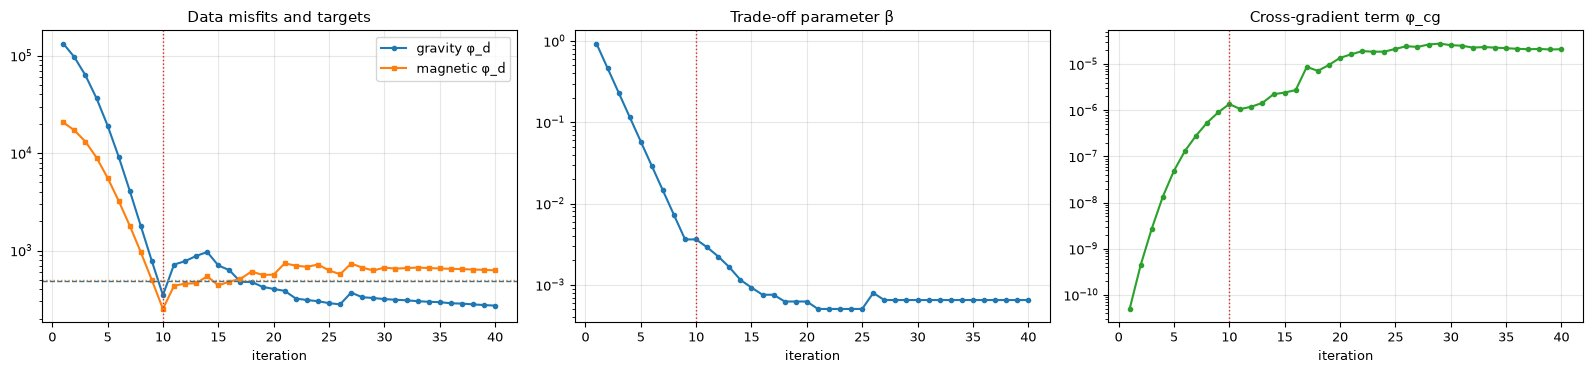

In [13]:
# 📊 RESULT
it = log.table
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].semilogy(it.iteration, it.phi_d_1, "o-", ms=3, label="gravity φ_d")
axes[0].semilogy(it.iteration, it.phi_d_2, "s-", ms=3, label="magnetic φ_d")
axes[0].axhline(len(g_obs), color="C0", ls="--", lw=1); axes[0].axhline(len(m_obs), color="C1", ls=":", lw=1)
axes[0].set(xlabel="iteration", title="Data misfits and targets"); axes[0].legend()
axes[1].semilogy(it.iteration, it.beta_1, "o-", ms=3)
axes[1].set(xlabel="iteration", title="Trade-off parameter β")
axes[2].semilogy(it.iteration, it.cross_gradient, "o-", ms=3, color="C2")
axes[2].set(xlabel="iteration", title="Cross-gradient term φ_cg")
for ax in axes:
    ax.axvline(irls_start, color="C3", lw=1, ls=":")
plt.tight_layout()
plt.show()

## 6  Data fit

Both data sets must be fitted as well as in the separate inversions; the coupling only chooses, among the models that
fit, those with similar structure.

In [14]:
# ▶ PROCESSING
g_pred = -g_sim.dpred(m_joint)
m_pred = m_sim.dpred(m_joint)
g_nres, m_nres = (g_obs - g_pred) / g_unc, (m_obs - m_pred) / m_unc
fit = pd.DataFrame({"separate": [np.sqrt(np.mean((sep_g["data_mgal"] - sep_g["predicted_mgal"]) ** 2)),
                                 np.sqrt(np.mean((sep_m["data_nT"] - sep_m["predicted_nT"]) ** 2))],
                    "joint": [np.sqrt(np.mean((g_obs - g_pred) ** 2)), np.sqrt(np.mean((m_obs - m_pred) ** 2))],
                    "joint χ²": [np.mean(g_nres ** 2), np.mean(m_nres ** 2)]}, index=["gravity rms [mGal]", "magnetic rms [nT]"])
fit.round(3)

,separate,joint,joint χ²
gravity rms [mGal],0.095,0.071,0.565
magnetic rms [nT],21.481,24.527,1.261


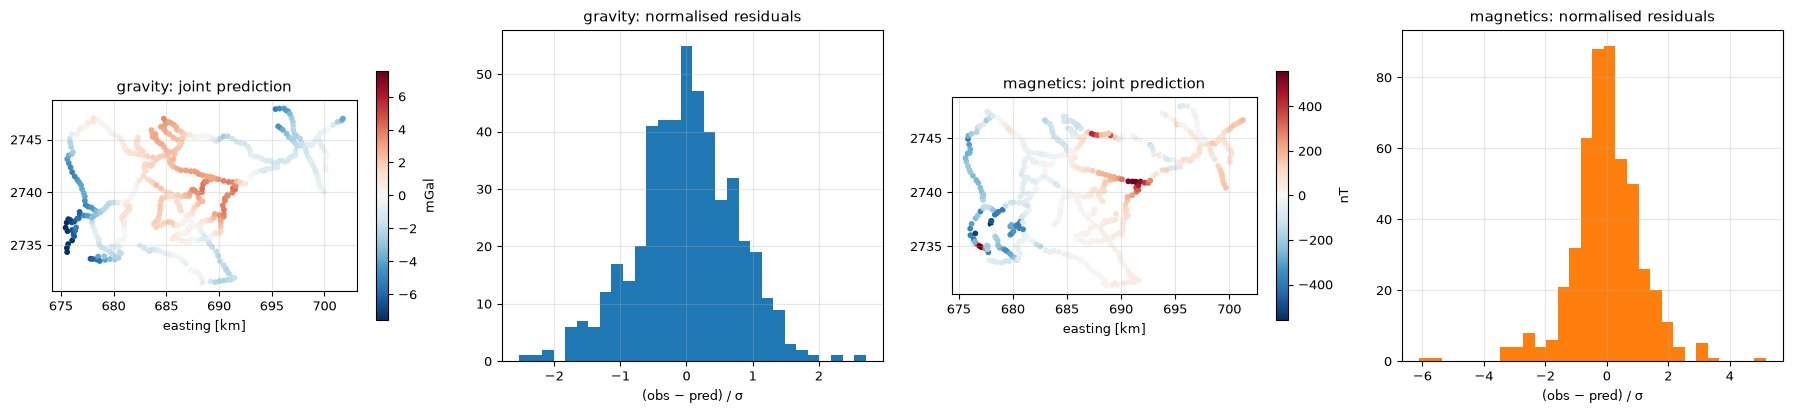

In [15]:
# 📊 RESULT
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for k, (df, obs, pred, nres, unit, name) in enumerate(((gb, g_obs, g_pred, g_nres, "mGal", "gravity"), (mb, m_obs, m_pred, m_nres, "nT", "magnetics"))):
    lim = np.percentile(np.abs(obs), 99)
    sc = axes[2 * k].scatter(df.e / 1000, df.n / 1000, c=pred, s=10, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[2 * k].set(aspect="equal", title=f"{name}: joint prediction", xlabel="easting [km]")
    plt.colorbar(sc, ax=axes[2 * k], label=unit, shrink=0.75)
    axes[2 * k + 1].hist(nres, bins=30, color=f"C{k}")
    axes[2 * k + 1].set(title=f"{name}: normalised residuals", xlabel="(obs − pred) / σ")
plt.tight_layout()
plt.show()

## 7  Separate and joint models

Slices at one elevation and a section, for both properties, from the separate (left) and the joint (right)
inversions. Blank: farther than `MASK_M` from any data point.

In [16]:
# ✏️ PARAMETERS – edit and re-run from here
SLICE_ELEVATION_M = -600.0
MASK_M = 2500.0
SECTIONS = {"A–B (notebook 04)": ((34.7448, 24.7058), (34.9490, 24.8117)),
            "S–N through the SW anomaly": ((34.749, 24.700), (34.749, 24.752))}
SECTION_ZMIN_M = -2500.0

In [17]:
# ▶ PROCESSING
full = {"rho_sep": W.model_on_mesh(mesh, active, rho_sep), "rho_joint": W.model_on_mesh(mesh, active, rho_joint),
        "chi_sep": W.model_on_mesh(mesh, active, chi_sep), "chi_joint": W.model_on_mesh(mesh, active, chi_joint)}
rlim = np.percentile(np.abs(np.r_[rho_sep, rho_joint]), 99)
clim = np.percentile(np.r_[chi_sep, chi_joint], 99.5)
all_e, all_n = np.r_[gb.e, mb.e], np.r_[gb.n, mb.n]
print(f"joint: Δρ {rho_joint.min():.3f} … {rho_joint.max():.3f} g/cm³; χ {chi_joint.min():.4f} … {chi_joint.max():.4f} SI")

joint: Δρ -0.300 … 0.300 g/cm³; χ 0.0000 … 0.3000 SI


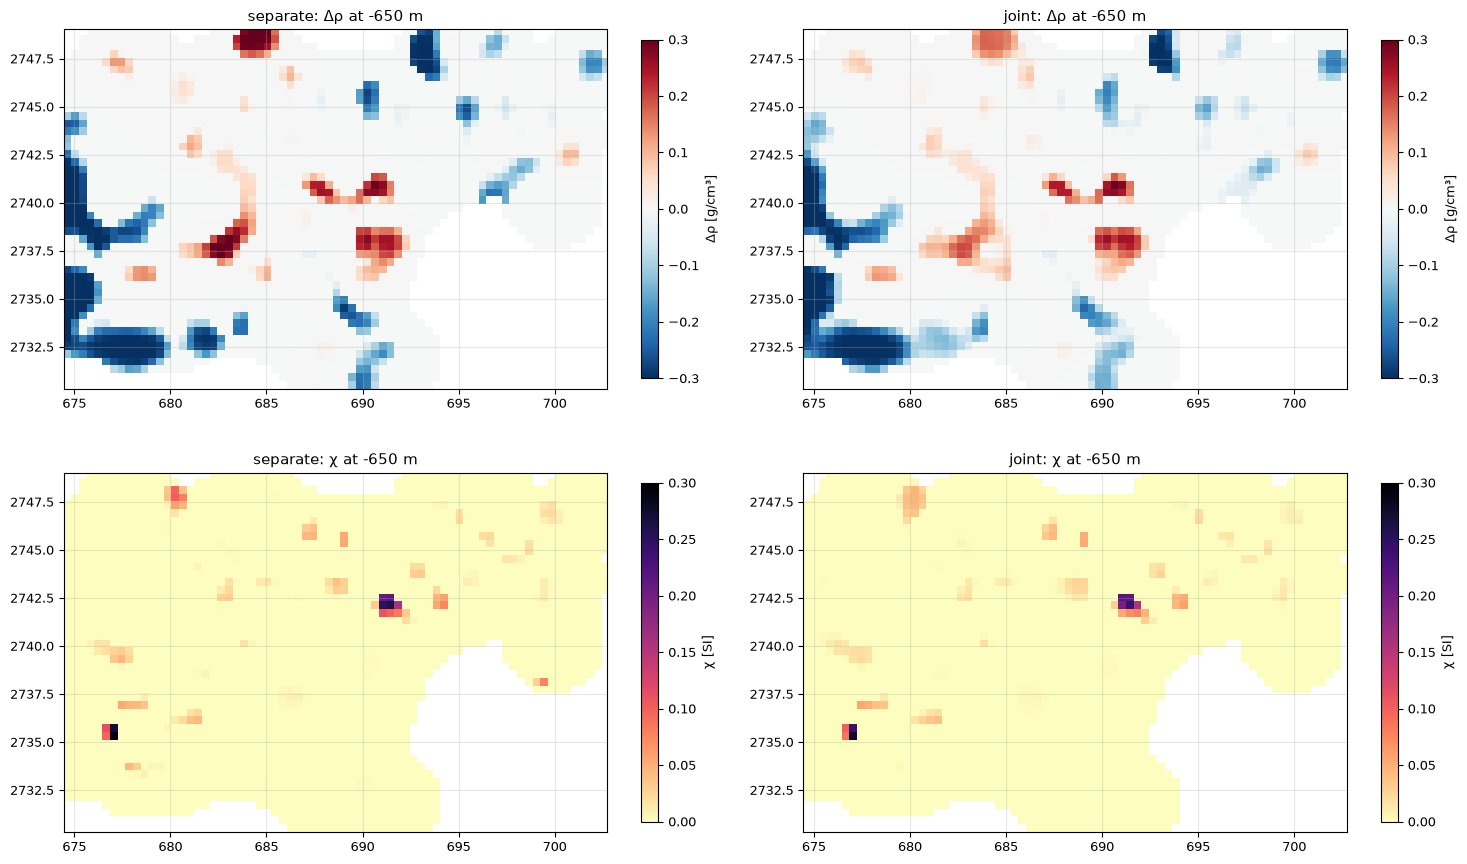

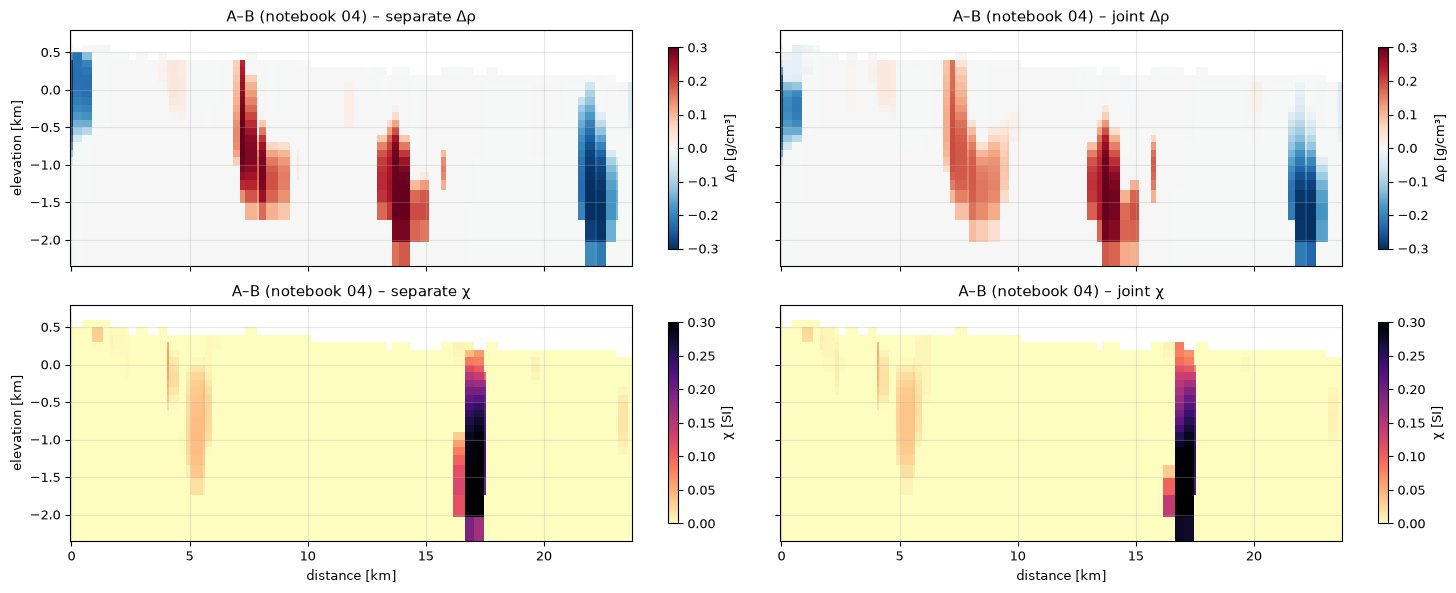

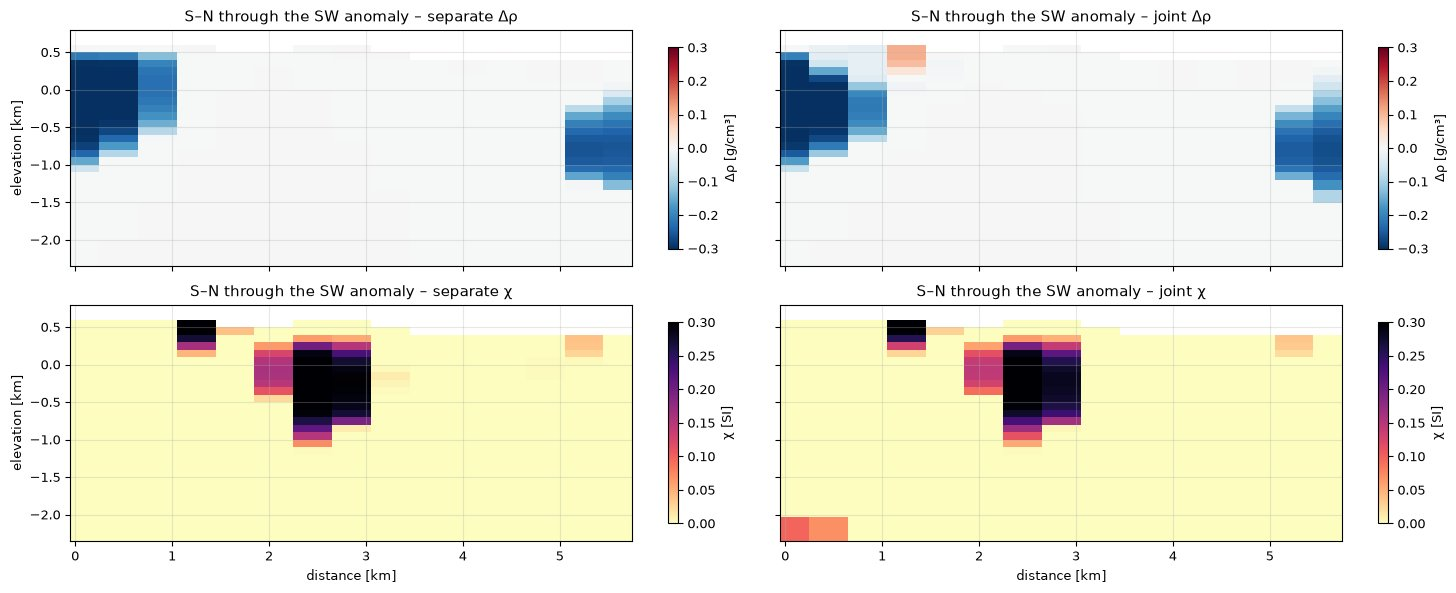

In [18]:
# 📊 RESULT
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for r, (prop, cmap, vmin, vmax, unit) in enumerate((("rho", "RdBu_r", -rlim, rlim, "Δρ [g/cm³]"), ("chi", "magma_r", 0, clim, "χ [SI]"))):
    for c, kind in enumerate(("sep", "joint")):
        x, y, s2, zz = W.depth_slice(mesh, full[f"{prop}_{kind}"], -SLICE_ELEVATION_M, 0.0)
        s2 = np.where(W.far_from_data(x, y, all_e, all_n, MASK_M), np.nan, s2)
        m = axes[r, c].pcolormesh(x / 1000, y / 1000, s2, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        axes[r, c].set(aspect="equal", xlim=(region[0] / 1000, region[1] / 1000), ylim=(region[2] / 1000, region[3] / 1000),
                       title=f"{'separate' if kind == 'sep' else 'joint'}: {unit.split()[0]} at {zz:.0f} m")
        plt.colorbar(m, ax=axes[r, c], label=unit, shrink=0.8)
plt.tight_layout()
plt.show()

for name, (a, b) in SECTIONS.items():
    (ea, na), (eb, nb_) = W.to_utm(*a), W.to_utm(*b)
    fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharex=True, sharey=True)
    for r, (prop, cmap, vmin, vmax, unit) in enumerate((("rho", "RdBu_r", -rlim, rlim, "Δρ [g/cm³]"), ("chi", "magma_r", 0, clim, "χ [SI]"))):
        for c, kind in enumerate(("sep", "joint")):
            d, zc, sec = W.section(mesh, full[f"{prop}_{kind}"], (ea, na), (eb, nb_), zmin=SECTION_ZMIN_M)
            m = axes[r, c].pcolormesh(d / 1000, zc / 1000, sec, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
            axes[r, c].set(title=f"{name} – {'separate' if kind == 'sep' else 'joint'} {unit.split()[0]}")
            plt.colorbar(m, ax=axes[r, c], label=unit, shrink=0.85)
    for ax in axes[1]:
        ax.set_xlabel("distance [km]")
    for ax in axes[:, 0]:
        ax.set_ylabel("elevation [km]")
    plt.tight_layout()
    plt.show()

## 8  Structural similarity

The normalised cross-gradient t = |∇ρ × ∇χ| / (|∇ρ| |∇χ|) is the sine of the angle between the two gradients:
0 where the boundaries of the two models are parallel, 1 where they cross at right angles. It is shown only where
both models change markedly (|∇ρ| |∇χ| in its top 10 %): where one model is flat the angle has no meaning, and that
is also where the coupling term has no effect. The gradient-weighted mean s = Σ|∇ρ × ∇χ|² / Σ|∇ρ|²|∇χ|² over all
active cells summarises a whole model pair (0 = identical structure).

In [19]:
# ▶ PROCESSING
core = (region[0] + REGION_PAD_M, region[1] - REGION_PAD_M, region[2] + REGION_PAD_M, region[3] - REGION_PAD_M)
t_sep, s_sep = W.cross_gradient(mesh, active, rho_sep, chi_sep, core=core)
t_joint, s_joint = W.cross_gradient(mesh, active, rho_joint, chi_joint, core=core)
print(f"structural dissimilarity s: separate {s_sep:.3f} -> joint {s_joint:.3f}  ({(1 - s_joint / s_sep) * 100:.0f} % lower)")

structural dissimilarity s: separate 0.259 -> joint 0.073  (72 % lower)


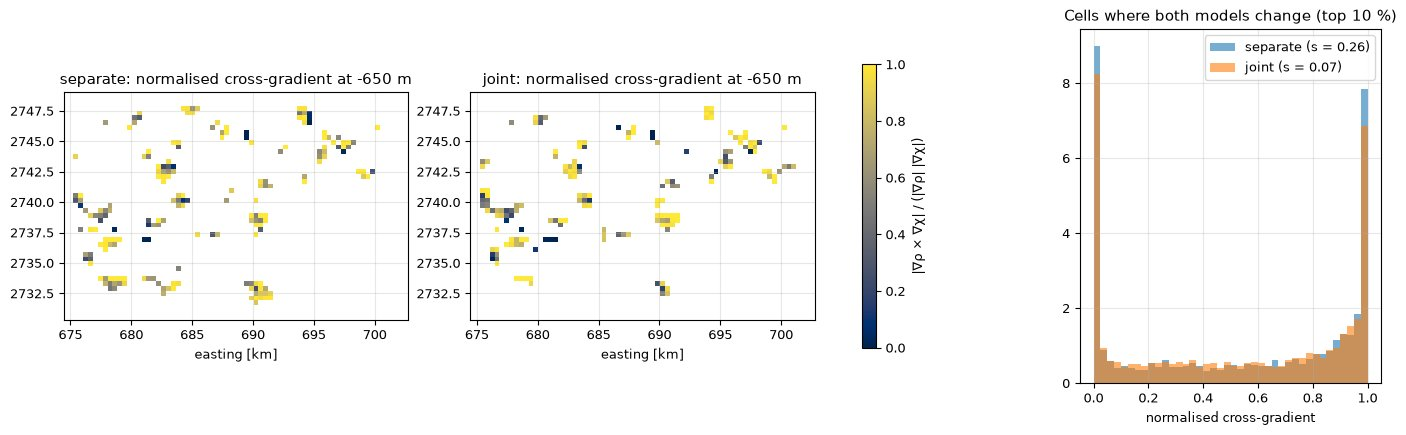

In [20]:
# 📊 RESULT
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.7]})
for ax, t, title in ((axes[0], t_sep, "separate"), (axes[1], t_joint, "joint")):
    x, y, s2, zz = W.depth_slice(mesh, t, -SLICE_ELEVATION_M, 0.0)
    s2 = np.where(W.far_from_data(x, y, all_e, all_n, MASK_M), np.nan, s2)
    m = ax.pcolormesh(x / 1000, y / 1000, s2, cmap="cividis", vmin=0, vmax=1, shading="auto")
    ax.set(aspect="equal", xlim=(region[0] / 1000, region[1] / 1000), ylim=(region[2] / 1000, region[3] / 1000),
           title=f"{title}: normalised cross-gradient at {zz:.0f} m", xlabel="easting [km]")
plt.colorbar(m, ax=axes[:2], label="|∇ρ × ∇χ| / (|∇ρ| |∇χ|)", shrink=0.8)
axes[2].hist(t_sep[np.isfinite(t_sep)], bins=40, alpha=0.6, label=f"separate (s = {s_sep:.2f})", density=True)
axes[2].hist(t_joint[np.isfinite(t_joint)], bins=40, alpha=0.6, label=f"joint (s = {s_joint:.2f})", density=True)
axes[2].set(xlabel="normalised cross-gradient", title="Cells where both models change (top 10 %)"); axes[2].legend()
plt.show()

## 9  Density against susceptibility

With similar structure, the cells of the joint model group into a few populations in the Δρ–χ plane, much more
clearly than the separate models. A simple joint classification by thresholds turns these populations into units:

| Unit | Δρ | χ | Possible rocks |
|---|---|---|---|
| dense and magnetic | > `RHO_T` | > `CHI_T` | mafic–ultramafic intrusions, serpentinite, BIF |
| dense, non-magnetic | > `RHO_T` | ≤ `CHI_T` | metasediments, dense metavolcanics |
| light, magnetic | < −`RHO_T` | > `CHI_T` | magnetite-bearing granitoids |
| light, non-magnetic | < −`RHO_T` | ≤ `CHI_T` | sediments of the wadis, altered or fractured rock, granite |
| background | otherwise | | |

The thresholds are a starting point for interpretation, not a geological map.

In [21]:
# ✏️ PARAMETERS – edit and re-run from here
RHO_T = 0.02    # g/cm³
CHI_T = 0.005   # SI

In [22]:
# ▶ PROCESSING
def classify(rho, chi):
    u = np.zeros(len(rho), int)
    u[(rho > RHO_T) & (chi > CHI_T)] = 1
    u[(rho > RHO_T) & (chi <= CHI_T)] = 2
    u[(rho < -RHO_T) & (chi > CHI_T)] = 3
    u[(rho < -RHO_T) & (chi <= CHI_T)] = 4
    return u
UNITS = ["background", "dense, magnetic", "dense, non-magnetic", "light, magnetic", "light, non-magnetic"]
UCOL = ["#e8e8e8", "#7b1fa2", "#d84315", "#1e88e5", "#fdd835"]
u_sep, u_joint = classify(rho_sep, chi_sep), classify(rho_joint, chi_joint)
pd.DataFrame({"separate [% of cells]": np.bincount(u_sep, minlength=5) / len(u_sep) * 100,
              "joint [% of cells]": np.bincount(u_joint, minlength=5) / len(u_joint) * 100}, index=UNITS).round(1)

,separate [% of cells],joint [% of cells]
background,88.3,86.6
"dense, magnetic",0.2,0.2
"dense, non-magnetic",3.3,3.9
"light, magnetic",0.3,0.7
"light, non-magnetic",8.0,8.7


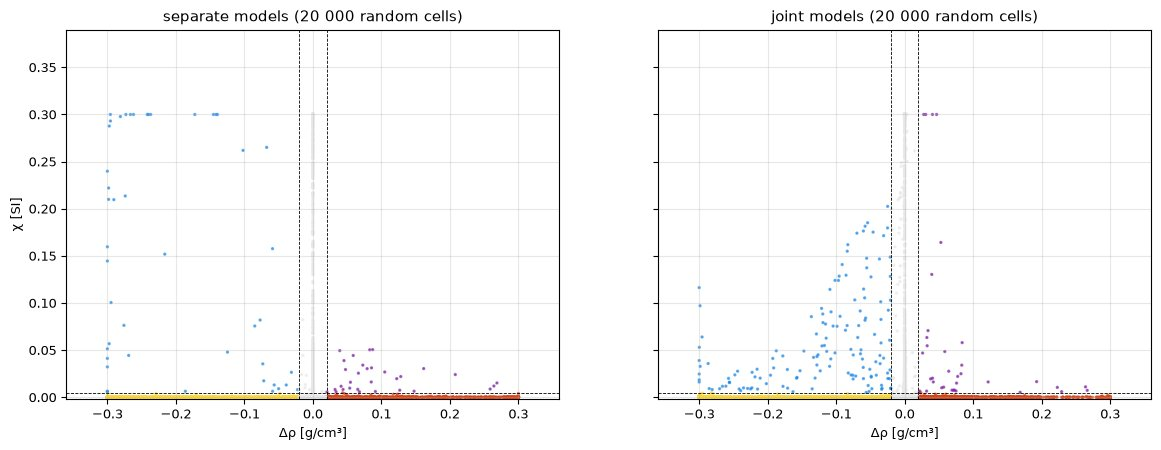

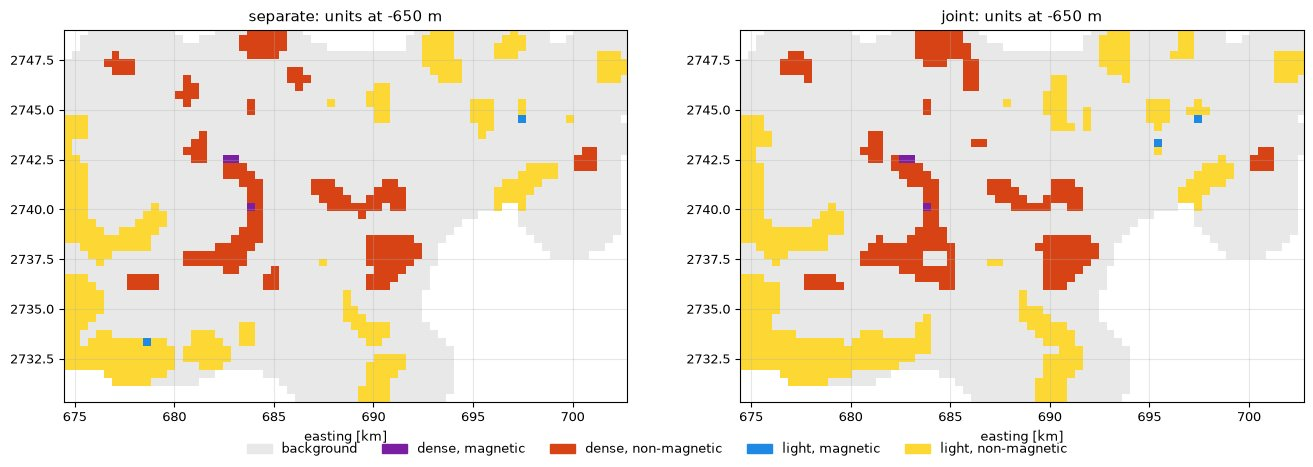

In [23]:
# 📊 RESULT
from matplotlib.colors import ListedColormap
rng = np.random.default_rng(0)
pick = rng.choice(n_active, size=min(20000, n_active), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, rho_, chi_, title in ((axes[0], rho_sep, chi_sep, "separate"), (axes[1], rho_joint, chi_joint, "joint")):
    ax.scatter(rho_[pick], chi_[pick], s=2, c=np.array(UCOL)[classify(rho_[pick], chi_[pick])], alpha=0.6)
    ax.axvline(RHO_T, color="k", lw=0.6, ls="--"); ax.axvline(-RHO_T, color="k", lw=0.6, ls="--"); ax.axhline(CHI_T, color="k", lw=0.6, ls="--")
    ax.set(xlabel="Δρ [g/cm³]", title=f"{title} models (20 000 random cells)", xlim=(-rlim * 1.2, rlim * 1.2), ylim=(-0.002, clim * 1.3))
axes[0].set_ylabel("χ [SI]")
plt.show()

cmap_u = ListedColormap(UCOL)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, u, title in ((axes[0], u_sep, "separate"), (axes[1], u_joint, "joint")):
    x, y, s2, zz = W.depth_slice(mesh, W.model_on_mesh(mesh, active, u.astype(float)), -SLICE_ELEVATION_M, 0.0)
    s2 = np.where(W.far_from_data(x, y, all_e, all_n, MASK_M), np.nan, s2)
    ax.pcolormesh(x / 1000, y / 1000, s2, cmap=cmap_u, vmin=-0.5, vmax=4.5, shading="auto")
    ax.set(aspect="equal", xlim=(region[0] / 1000, region[1] / 1000), ylim=(region[2] / 1000, region[3] / 1000),
           title=f"{title}: units at {zz:.0f} m", xlabel="easting [km]")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in UCOL]
fig.legend(handles, UNITS, loc="lower center", ncol=5, frameon=False)
plt.show()

## 10  Export

`outputs/inversion/`: the joint models (NumPy and UBC-GIF), the unit model, the iteration log and a summary with the
fit and the structural similarity of the separate and joint models.

In [24]:
# ▶ PROCESSING
np.savez_compressed(os.path.join(OUT_DIR, "joint_model.npz"), rho_gcc=rho_joint, chi_SI=chi_joint, units=u_joint, active=active,
                    hx=mesh.h[0], hy=mesh.h[1], hz=mesh.h[2], origin=mesh.origin, lambda_cg=LAMBDA_CG)
files = W.save_ubc(mesh, {"density_gcc": full["rho_joint"], "susceptibility_SI": full["chi_joint"],
                          "units": W.model_on_mesh(mesh, active, u_joint.astype(float))}, os.path.join(OUT_DIR, "ubc"), "wadi_ghadir_joint")
log.table.to_csv(os.path.join(OUT_DIR, "joint_iterations.csv"), index=False)
summary = {"written_by": W.AUTHOR, "lambda_cg": LAMBDA_CG, "norms": list(NORMS), "irls_start": int(irls_start), "iterations": len(log.rows), "seconds": round(seconds, 1),
           "gravity": {"data": int(len(g_obs)), "rms_mgal": float(fit.loc["gravity rms [mGal]", "joint"]), "chi2": float(np.mean(g_nres ** 2))},
           "magnetics": {"data": int(len(m_obs)), "rms_nT": float(fit.loc["magnetic rms [nT]", "joint"]), "chi2": float(np.mean(m_nres ** 2))},
           "structural_dissimilarity": {"separate": s_sep, "joint": s_joint},
           "units_percent": {"separate": dict(zip(UNITS, (np.bincount(u_sep, minlength=5) / len(u_sep) * 100).round(2).tolist())),
                             "joint": dict(zip(UNITS, (np.bincount(u_joint, minlength=5) / len(u_joint) * 100).round(2).tolist()))},
           "thresholds": {"rho_gcc": RHO_T, "chi_SI": CHI_T}}
json.dump(summary, open(os.path.join(OUT_DIR, "joint_summary.json"), "w"), indent=1)
print("written:", sorted(f for f in os.listdir(OUT_DIR) if f.startswith("joint")), files)

written: ['joint_iterations.csv', 'joint_model.npz', 'joint_summary.json'] ['wadi_ghadir_joint_density_gcc.mod', 'wadi_ghadir_joint_mesh.msh', 'wadi_ghadir_joint_susceptibility_SI.mod', 'wadi_ghadir_joint_units.mod']


---
### References

* Gallardo, L. A. & Meju, M. A. (2003). Characterization of heterogeneous near-surface materials by joint 2D inversion of dc resistivity and seismic data. *Geophysical Research Letters* 30.
* Haber, E. & Oldenburg, D. W. (1997). Joint inversion: a structural approach. *Inverse Problems* 13.
* Fournier, D., Heagy, L. J. & Oldenburg, D. W. (2020). Sparse magnetic vector inversion in spherical coordinates; and the SimPEG joint-inversion tutorials (cross-gradient coupling of gravity and magnetic data).
* Cockett, R. et al. (2015). SimPEG. *Computers & Geosciences* 85.

*Written by Mohamed Sobh, LIAG.*